# Imports

##### standard python libraries

In [1]:
import pandas as pd
from sqlalchemy import create_engine

In [2]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [3]:
import psql_utilities as psql_utl
import graphviz_utilities as graphviz_utl

### Set Paths

In [4]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'

### Database Connection

In [5]:
db_config = psql_utl.load_config(path_conf_file)
### connect to the database - sqlalchemy
engine = create_engine(db_config['db_uri'])

## Visualize Simulation Runs

Metadati schema can be used to visualize the structure of experiment workflow as well as the execution of a single Simulation Run. 

Let us see what are the steps to design a query to retrieve the structure of the workflow of the experiment:

 1. First, we select the simulation runs of the experiment. Here we can decide how many simulation runs *num_srs* we want to visualize. Ideally, one could even select specific simulation runs.

 2. Then, we select all input/output datasets related to the given simulation runs

 3. Next, we associate to each simulation run all Global Input datasets related to the experiment

 4. Finally, we collect output from Step.2 and Step.3. As a result, we obtain a table containing the list of all graph edges


    

The full query SQL query can be found stored in *'./query_sr_graph.sql'*, one should just specify the number of simulation runs (*num_srs*) to visualize.

### setup

##### read query from file

In [6]:
query_sr = open("./query_sr_graph.sql", "r")
query_sr = query_sr.read()
#query_sr

##### set input variables

In [7]:
num_simulation_runs = 4

### query result

##### define input parameters

In [8]:
dict_params = {'num_srs': num_simulation_runs}

##### run query with pandas

In [9]:
df_graph = pd.read_sql(query_sr, con=engine,params=dict_params)
df_graph

,exp_id,sr_id,sr_name,ds_path,ds_name,ds_type
0,exp_ct_sr,sr_225478,E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E0...,CT-SR_M100/PS_001/E02020N3739E02658N3366-PS-St...,C_CT_flowdepth.nc,product
1,exp_ct_sr,sr_225478,E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E0...,CT-SR_M100/PS_001/E02020N3739E02658N3366-PS-St...,C_CT.nc,output
2,exp_ct_sr,sr_225478,E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E0...,CT-SR_M100/PS_001/E02020N3739E02658N3366-PS-St...,C_SR_flowdepth.nc,product
3,exp_ct_sr,sr_225478,E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E0...,CT-SR_M100/PS_001/E02020N3739E02658N3366-PS-St...,C_SR.nc,output
4,exp_ct_sr,sr_225478,E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E0...,CT-SR_M100/PS_001/E02020N3739E02658N3366-PS-St...,grid0_ts.nc,output
...,...,...,...,...,...,...
67,exp_ct_sr,sr_225481,E01964N3926E02184N3685-PS-Mur_PYes_Var-M792_E0...,CT-SR_M100/SIMULATION_SETUP/med09174_BS_probs9...,med09174_BS_probs99.csv,global_product
68,exp_ct_sr,sr_225478,E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E0...,CT-SR_M100/SIMULATION_SETUP/med09174_PS_probs9...,med09174_PS_probs99.csv,global_product
69,exp_ct_sr,sr_225479,E02020N3739E02658N3366-PS-Mur_PNo_Hom-M809_E02...,CT-SR_M100/SIMULATION_SETUP/med09174_PS_probs9...,med09174_PS_probs99.csv,global_product
70,exp_ct_sr,sr_225480,E02020N3739E02658N3366-PS-Mur_PYes_Var-M850_E0...,CT-SR_M100/SIMULATION_SETUP/med09174_PS_probs9...,med09174_PS_probs99.csv,global_product


**NOTE:** Here, the fields ds_path and sr_id identify the name of the two nodes whereas ds_type specifies the direction of the edge connecting them. These fields can be enriched by including all other attributes of simulation runs and datasets. By using a standard graph visualization tool as graphviz one can reproduce a graphical representation of the experiment workflow.

### visualize result

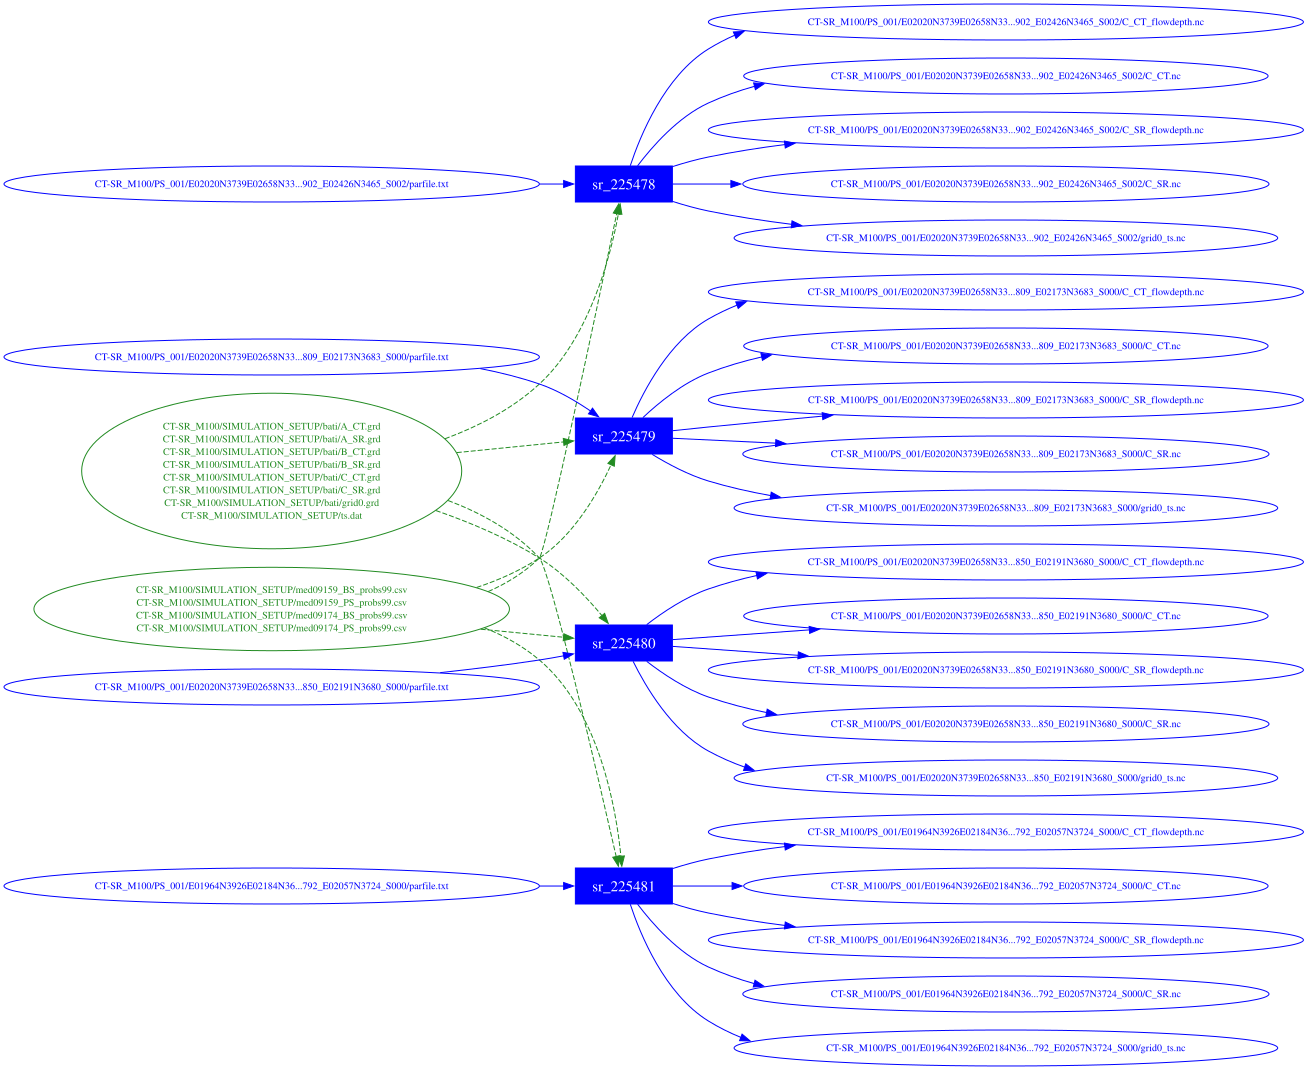

In [12]:
graph_sr = graphviz_utl.build_graph_from_df_v2(df_graph)
graph_sr
#
### to save the graph as pdf
#graph_sr.view()

**NOTE:** The figure above shows a graphical representation of the simulation runs in the experiment workflow: the blue boxes represent the simulation runs while the ellipses represent the input and output datasets and data products. We used the green color for ellipses to identify the global input datasets.